# Recurrence Graph Models: C-index Demonstration

A brief mentor-facing comparison of the two retained patient-graph models. The primary endpoint is progression by 36 months (`pfs_36m`), and the primary metric is Harrell's C-index. AUROC and AUPRC are shown as secondary diagnostics.

## What changed

- Removed the slow model zoo from the default experiment loop.
- Kept GraphSAGE and relation-aware RGCN as the graph comparison.
- Reduced the default benchmark to 3 folds and 12 maximum epochs for iteration.
- This final comparison used 5 folds, fixed 2-hop PrimeKG context, C-index loss, and C-index early stopping.
- Clinical logistic regression is intentionally not part of this graph-focused presentation.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'outputs').exists():
    ROOT = ROOT.parent
RUN = ROOT / 'outputs' / 'graph_models_cindex_5fold'
summary = pd.read_csv(RUN / 'metrics_summary.csv')
folds = pd.read_csv(RUN / 'metrics_folds.csv')
oof = pd.read_csv(RUN / 'oof_predictions.csv')
with (RUN / 'label_audit.json').open(encoding='utf-8') as handle:
    audit = json.load(handle)

print(f"Endpoint: {audit['endpoint']} | patients: {audit['patients']} | events: {audit['positives']}")
print(f"Comparable survival pairs: {audit['survival_pairs']['comparable_pairs']:,}")
display(summary[['model', 'auroc_mean', 'auprc_mean', 'c_index_mean', 'c_index_std']])

Endpoint: pfs_36m | patients: 498 | events: 89
Comparable survival pairs: 40,317


,model,auroc_mean,auprc_mean,c_index_mean,c_index_std
0,graphsage,0.664566,0.385552,0.646787,0.061119
1,rgcn,0.679888,0.399011,0.663973,0.064597


## Symbolic patient-graph reasoning

The graph is an evidence path, not a causal proof. A model score can be read with this symbolic template:

`Patient -> Sample -> altered Gene -> PrimeKG relation -> pathway / drug / disease node`

A message-passing model aggregates these typed paths into a patient risk score. For example, an altered gene connected to a breast-cancer disease node contributes graph context; it does not prove that the gene caused recurrence or that a drug will work. Follow-up time and event status are targets only and never enter the graph features.

In [2]:
reasoning_rules = pd.DataFrame({
    'graph fact': [
        'Patient is linked to a tumor Sample',
        'Sample carries a mutation or extreme CNA in a panel Gene',
        'Gene is connected in PrimeKG to a typed biological node',
        'Message passing aggregates these facts into patient risk'
    ],
    'interpretation boundary': [
        'Identity and sample linkage',
        'Observed molecular alteration',
        'Knowledge-graph association, not causality',
        'Predictive score, not a treatment recommendation'
    ]
})
display(reasoning_rules)

,graph fact,interpretation boundary
0,Patient is linked to a tumor Sample,Identity and sample linkage
1,Sample carries a mutation or extreme CNA in a ...,Observed molecular alteration
2,Gene is connected in PrimeKG to a typed biolog...,"Knowledge-graph association, not causality"
3,Message passing aggregates these facts into pa...,"Predictive score, not a treatment recommendation"


## Primary result: concordance

C-index asks whether a model ranks the earlier-event patient as higher risk among comparable patient pairs. It is the main result because censoring makes a simple binary interpretation of all non-events unreliable.

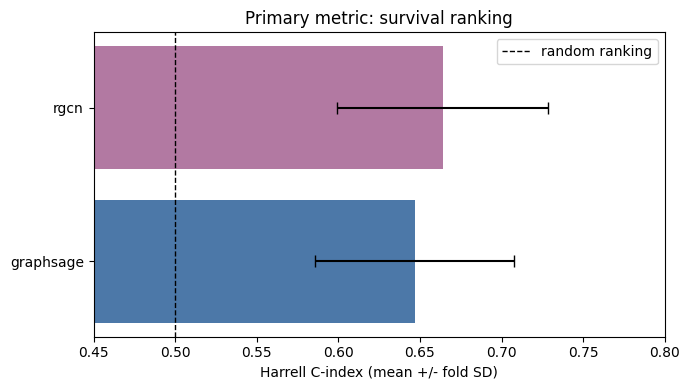

In [3]:
plot = summary.sort_values('c_index_mean').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(plot['model'], plot['c_index_mean'], xerr=plot['c_index_std'], color=['#4C78A8', '#B279A2'], capsize=4)
ax.axvline(0.5, color='black', linestyle='--', linewidth=1, label='random ranking')
ax.set_xlim(0.45, 0.8)
ax.set_xlabel('Harrell C-index (mean +/- fold SD)')
ax.set_title('Primary metric: survival ranking')
ax.legend()
fig.tight_layout()
plt.show()

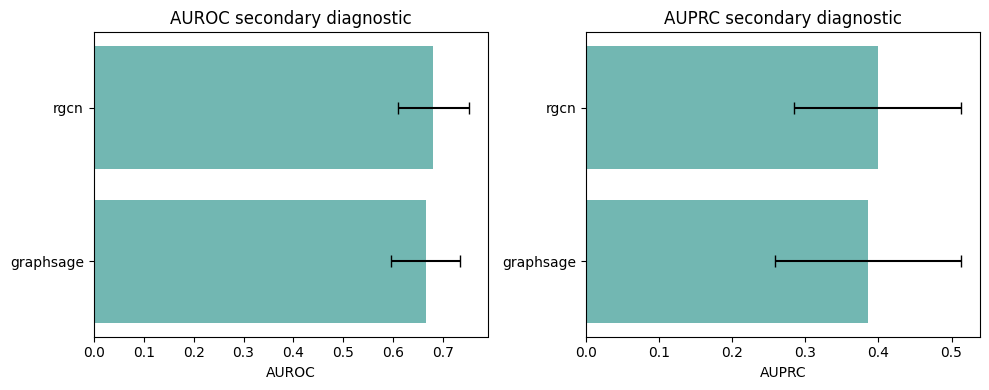

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
metric_specs = [('auroc_mean', 'auroc_std', 'AUROC'), ('auprc_mean', 'auprc_std', 'AUPRC')]
for ax, (mean_col, std_col, label) in zip(axes, metric_specs):
    plot = summary.sort_values(mean_col).reset_index(drop=True)
    ax.barh(plot['model'], plot[mean_col], xerr=plot[std_col], capsize=4, color='#72B7B2')
    ax.set_title(label + ' secondary diagnostic')
    ax.set_xlabel(label)
fig.tight_layout()
plt.show()

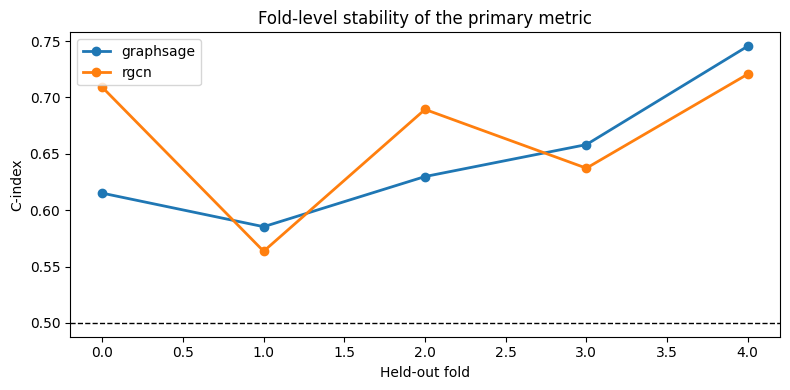

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for model, group in folds.groupby('model'):
    ax.plot(group['fold'], group['c_index'], marker='o', linewidth=2, label=model)
ax.axhline(0.5, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Held-out fold')
ax.set_ylabel('C-index')
ax.set_title('Fold-level stability of the primary metric')
ax.legend()
fig.tight_layout()
plt.show()

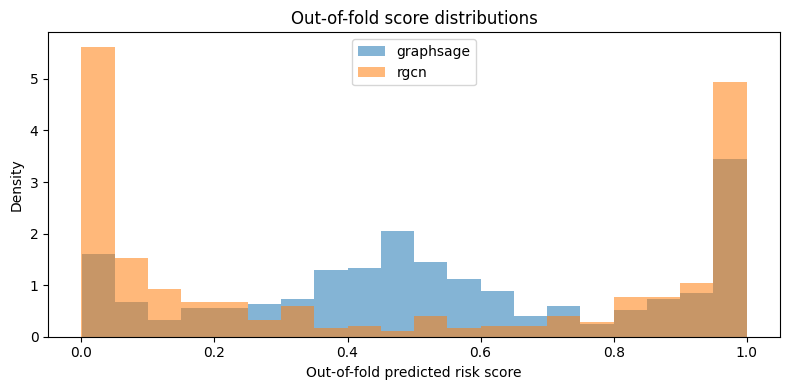

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
for model, group in oof.groupby('model'):
    ax.hist(group['probability'], bins=20, alpha=0.55, density=True, label=model)
ax.set_xlabel('Out-of-fold predicted risk score')
ax.set_ylabel('Density')
ax.set_title('Out-of-fold score distributions')
ax.legend()
fig.tight_layout()
plt.show()

## Additional GNN sanity check

Three other popular architectures were trained with the same fixed 2-hop graph: GCN, GIN, and Transformer. This compact check uses 3 folds, C-index loss, and C-index early stopping. These models are controls, not new defaults.

,model,protocol,c_index_mean,c_index_std,auroc_mean,auprc_mean
0,graphsage,5-fold primary comparison,0.646787,0.061119,0.664566,0.385552
1,rgcn,5-fold primary comparison,0.663973,0.064597,0.679888,0.399011
2,gcn,3-fold sanity check,0.638348,0.054845,0.655074,0.336084
3,gin,3-fold sanity check,0.528984,0.105244,0.529674,0.264760
4,transformer,3-fold sanity check,0.636798,0.049708,0.650237,0.369681


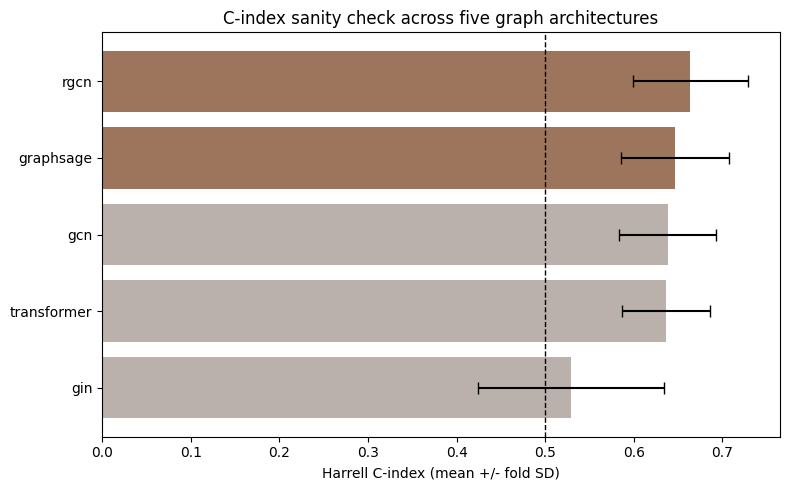

In [2]:
sanity = pd.read_csv(ROOT / 'outputs' / 'gnn_sanity_cindex_3extra' / 'metrics_summary.csv')
combined = pd.concat([
    summary.assign(protocol='5-fold primary comparison'),
    sanity.assign(protocol='3-fold sanity check'),
], ignore_index=True)
display(combined[['model', 'protocol', 'c_index_mean', 'c_index_std', 'auroc_mean', 'auprc_mean']])

plot = combined.sort_values('c_index_mean').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#9D755D' if model in {'rgcn', 'graphsage'} else '#BAB0AC' for model in plot['model']]
ax.barh(plot['model'], plot['c_index_mean'], xerr=plot['c_index_std'], color=colors, capsize=4)
ax.axvline(0.5, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Harrell C-index (mean +/- fold SD)')
ax.set_title('C-index sanity check across five graph architectures')
fig.tight_layout()
plt.show()

## Neuro-symbolic reasoning: one grounded chain

**Neural part:** the RGCN produces a patient risk score.  
**Symbolic part:** we trace real graph edges: `Patient -> Sample -> altered Gene -> PrimeKG node`.  
**Meaning:** the chain makes the score inspectable; it does not prove causality or recommend treatment.

In [2]:
explanations = pd.read_csv(ROOT / 'outputs' / 'graph_models_cindex_5fold' / 'explanations.csv')
explanations['path_length'] = explanations['path'].str.count('->')

print('Explanation model:', explanations['model'].iloc[0])
print('Score source:', explanations['score_source'].value_counts().to_dict())
print('Patients with paths:', explanations['patient_id'].nunique())

top_paths = (
    explanations.sort_values(['y_prob', 'path_score'], ascending=False)
    [['patient_id', 'y_true', 'y_prob', 'path_rank', 'path_score', 'score_source', 'path']]
    .head(10)
)
display(top_paths)

Explanation model: rgcn
Score source: {'altered_gene_prior': 24}
Patients with paths: 8


,patient_id,y_true,y_prob,path_rank,path_score,score_source,path
0,TCGA-B6-A409,1,1.000000,1,0.8,altered_gene_prior,patient:TCGA-B6-A409 -has_sample-> sample:TCGA...
1,TCGA-B6-A409,1,1.000000,2,0.8,altered_gene_prior,patient:TCGA-B6-A409 -has_sample-> sample:TCGA...
2,TCGA-B6-A409,1,1.000000,3,0.8,altered_gene_prior,patient:TCGA-B6-A409 -has_sample-> sample:TCGA...
3,TCGA-B6-A0IK,1,0.999997,1,0.8,altered_gene_prior,patient:TCGA-B6-A0IK -has_sample-> sample:TCGA...
4,TCGA-B6-A0IK,1,0.999997,2,0.8,altered_gene_prior,patient:TCGA-B6-A0IK -has_sample-> sample:TCGA...
5,TCGA-B6-A0IK,1,0.999997,3,0.8,altered_gene_prior,patient:TCGA-B6-A0IK -has_sample-> sample:TCGA...
6,TCGA-A8-A08O,1,0.999992,1,0.8,altered_gene_prior,patient:TCGA-A8-A08O -has_sample-> sample:TCGA...
7,TCGA-A8-A08O,1,0.999992,2,0.8,altered_gene_prior,patient:TCGA-A8-A08O -has_sample-> sample:TCGA...
8,TCGA-A8-A08O,1,0.999992,3,0.8,altered_gene_prior,patient:TCGA-A8-A08O -has_sample-> sample:TCGA...
9,TCGA-BH-A1F8,1,0.999988,1,0.8,altered_gene_prior,patient:TCGA-BH-A1F8 -has_sample-> sample:TCGA...


In [3]:
best_chain = explanations.sort_values(['y_prob', 'path_score'], ascending=False).iloc[0]
print('Best available symbolic chain for the highest-risk explained patient:')
print(best_chain['path'])
print()
print('Interpretation: this chain is supported by observed patient graph edges and the PrimeKG relation labels.')
print('It is not evidence that the chain caused recurrence, and it is not a treatment recommendation.')

Best available symbolic chain for the highest-risk explained patient:
patient:TCGA-B6-A409 -has_sample-> sample:TCGA-B6-A409-01 (TCGA-B6-A409-01) -has_high_level_amplification-> gene:CNST:163882 (CNST) -protein_protein-> gene:MYC:4609 (MYC) -pathway_protein-> pathway:R-HSA-8951430 (RUNX3 regulates WNT signaling)

Interpretation: this chain is supported by observed patient graph edges and the PrimeKG relation labels.
It is not evidence that the chain caused recurrence, and it is not a treatment recommendation.


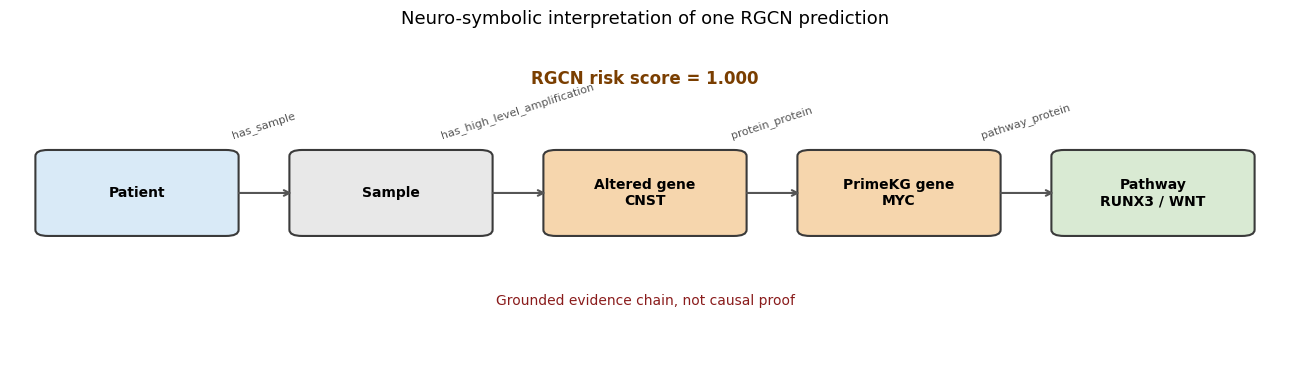

In [4]:
from matplotlib.patches import FancyBboxPatch

nodes = [
    ('Patient', '#D9EAF7'),
    ('Sample', '#E8E8E8'),
    ('Altered gene\nCNST', '#F6D6AD'),
    ('PrimeKG gene\nMYC', '#F6D6AD'),
    ('Pathway\nRUNX3 / WNT', '#D9EAD3'),
]
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.set_xlim(-0.5, len(nodes) - 0.5)
ax.set_ylim(-0.8, 1.8)
ax.axis('off')

for index, (label, color) in enumerate(nodes):
    box = FancyBboxPatch(
        (index - 0.36, 0.25), 0.72, 0.62,
        boxstyle='round,pad=0.04,rounding_size=0.05',
        linewidth=1.5, edgecolor='#3A3A3A', facecolor=color,
    )
    ax.add_patch(box)
    ax.text(index, 0.56, label, ha='center', va='center', fontsize=10, weight='bold')

relations = ['has_sample', 'has_high_level_amplification', 'protein_protein', 'pathway_protein']
for index, relation in enumerate(relations):
    ax.annotate(
        '', xy=(index + 0.62, 0.56), xytext=(index + 0.39, 0.56),
        arrowprops={'arrowstyle': '->', 'color': '#555555', 'linewidth': 1.5},
    )
    ax.text(index + 0.5, 0.98, relation, ha='center', va='bottom', fontsize=8, color='#555555', rotation=18)

ax.text(2, 1.45, f"RGCN risk score = {best_chain['y_prob']:.3f}", ha='center', fontsize=12, weight='bold', color='#7A3E00')
ax.text(2, -0.35, 'Grounded evidence chain, not causal proof', ha='center', fontsize=10, color='#8A1C1C')
ax.set_title('Neuro-symbolic interpretation of one RGCN prediction', fontsize=13, pad=12)
fig.tight_layout()
plt.show()